In [230]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

## Load in Pair Data and Control Data

In [231]:
parent = Table.read('out/parent.fits', unit_parse_strict = 'silent')
pairs = Table.read('out/pairs.fits', unit_parse_strict = 'silent')

in_sample = np.asarray(parent['in_sample'])
isolated = np.asarray(parent['isolated'])

# Extract data for SFR calculation
z = np.asarray(parent['Z'], dtype = float)
logM = np.asarray(parent['logmstar'], dtype = float)
sigma_logM = np.asarray(parent['dellogmstar'], dtype = float)
M_r = np.asarray(parent['absmag_r'], dtype = float)
sigma_M_r = np.asarray(parent['delabsmag_r'], dtype = float)
F_HA = np.asarray(parent['HA_FLUX'], dtype = float)
sigma_F_HA = np.asarray(parent['HA_FLUX_ERR'], dtype = float)
EW_HA = np.asarray(parent['HA_EW'], dtype = float)
sigma_EW_HA = np.asarray(parent['HA_EW_ERR'], dtype = float)
F_HB = np.asarray(parent['HB_FLUX'], dtype = float)
sigma_F_HB = np.asarray(parent['HB_FLUX_ERR'], dtype = float)

# Extract data for BPT diagram
F_NII_R = np.asarray(parent['NIIR_FLUX'], dtype = float)
sigma_F_NII_R = np.asarray(parent['NIIR_FLUX_ERR'], dtype = float)
F_OIII_R = np.asarray(parent['OIIIR_FLUX'], dtype = float)
sigma_F_OIII_R = np.asarray(parent['OIIIR_FLUX_ERR'], dtype = float)

## Calculate SFR

The $\text{H}\alpha$ luminosity is given by
$$ L_{\text{H}\alpha} = (\text{EW}_{\text{H}\alpha} + \text{EW}_c) \times 10^{-0.4 (M_r - 34.1)} \times \frac{3 \times 10^{18}}{[6564.1(1 + z)]^2} \bigg( \frac{F_{\text{H}\alpha} / F_{\text{H}\beta}}{2.86} \bigg)^{2.36} $$
The SFR is given by
$$ \text{SFR}_{\text{H}\alpha} \, (M_\odot \, \text{yr}^{-1}) = \frac{L_{\text{H}\alpha} \, (\text{W\,Hz}^{-1})}{1.27 \times 10^{34}} $$
(Davies et al. 2015)

In [232]:
with np.errstate(divide = 'ignore', invalid = 'ignore'):
    # Calculate the Balmer decrement, using the median for galaxies without valid measurements
    valid_BD = np.all([(F > 0) & (sigma > 0) & (F / sigma >= SN_MIN) for F, sigma in [(F_HA, sigma_F_HA), (F_HB, sigma_F_HB)]], axis = 0)
    BD_measured = np.clip(F_HA / F_HB, 2.86, None)
    BD_median = np.median(BD_measured[in_sample & valid_BD])
    BD = np.where(valid_BD, BD_measured, BD_median)

    # Calculate the H-alpha luminosity
    L_HA = np.clip(EW_HA + EW_C, 0.1, None) * 10 ** (-0.4 * (M_r - 34.1)) * 3e18 / (LAMBDA_HA * (1 + z)) ** 2 * (BD / 2.86) ** 2.36

    # Calculate the SFR and sSFR
    SFR = L_HA / 1.27e34
    log_SFR = np.log10(SFR)
    log_sSFR = log_SFR - logM

print(f'Median Balmer decrement used for undetected galaxies: {BD_median:.2f}')
print(f'Sample galaxies with a measured Balmer decrement: {np.sum(in_sample & valid_BD)} of {np.sum(in_sample)}')

Median Balmer decrement used for undetected galaxies: 4.60
Sample galaxies with a measured Balmer decrement: 25822 of 44022


## BPT Diagram

A galaxy is defined to be purely star forming if
$$ \log (F_\text{OIII} / F_{\text{H}\beta}) < \frac{0.61}{\log (F_\text{NII} / F_{\text{H}\alpha}) - 0.05} + 1.3 $$
(Kauffmann et al. 2003)
A galaxy contains an AGN if
$$ \log (F_\text{OIII} / F_{\text{H}\beta}) > \frac{0.61}{\log (F_\text{NII} / F_{\text{H}\alpha}) - 0.47} + 1.19 $$
(Kewley et al. 2001)
Galaxies between the two lines are composites

In [233]:
def kauffmann_line(log_NII_HA):
    """Kauffmann et al. (2003) line for the BPT diagram."""
    return 0.61 / (log_NII_HA - 0.05) + 1.3

def kewley_line(log_NII_HA):
    """Kewley et al. (2001) line for the BPT diagram."""
    return 0.61 / (log_NII_HA - 0.47) + 1.19

In [234]:
with np.errstate(divide = 'ignore', invalid = 'ignore'):
    # Calculate the log ratios for the BPT diagram
    log_OIII_HB = np.log10(F_OIII_R / F_HB)
    log_NII_HA = np.log10(F_NII_R / F_HA)

    # Only galaxies with all four BPT lines detected at S/N >= SN_MIN can be classified
    lines = [(F_HA, sigma_F_HA), (F_HB, sigma_F_HB), (F_NII_R, sigma_F_NII_R), (F_OIII_R, sigma_F_OIII_R)]
    detected = np.all([(F > 0) & (sigma > 0) & (F / sigma >= SN_MIN) for F, sigma in lines], axis = 0)

    # Classify galaxies into star-forming, composite, and AGN
    SF = detected & (log_NII_HA < 0.05) & (log_OIII_HB < kauffmann_line(log_NII_HA))
    AGN = detected & ((log_NII_HA >= 0.47) | (log_OIII_HB > kewley_line(log_NII_HA)))
    composite = detected & ~SF & ~AGN

print(f'Detected in all four lines: {np.sum(detected)} rows')
print(f'Star forming: {np.sum(SF)}, Composite: {np.sum(composite)}, AGN: {np.sum(AGN)}')

Detected in all four lines: 32339 rows
Star forming: 24666, Composite: 5448, AGN: 2227


## Re-Match Controls to Pairs with $\text{H}\alpha$ SFRs

In [235]:
def match_controls(k, ctrl_pool, z, logM, n_ctrl = N_CTRL, dz = DZ_TOL, dm = DLOGM_TOL):
    """
    Match control galaxies for a given primary galaxy based on redshift and stellar mass.
    
    Parameters
    ----------
    k : int
        Index of the primary galaxy in the parent table.
    ctrl_pool : array
        Indices of the potential control galaxies in the parent table.
    z : array
        Redshift values of the galaxies in the parent table.
    logM : array
        Logarithm of stellar mass values of the galaxies in the parent table.
    n_ctrl : int
        Number of control galaxies to match.
    dz : float
        Tolerance for redshift matching.
    dm : float
        Tolerance for stellar mass matching.
    
    Returns
    -------
    ctrl_sample : array
        Indices of the matched control galaxies in the parent table.
    """

    # Filter the control pool based on redshift and stellar mass tolerances
    ctrl = (np.abs(z[ctrl_pool] - z[k]) <= dz) & (np.abs(logM[ctrl_pool] - logM[k]) <= dm)
    ctrl_candidates = ctrl_pool[ctrl]

    # If there are not enough candidates, return None
    if len(ctrl_candidates) < n_ctrl:
        return None

    # Calculate the distance metric for the candidates
    d = np.hypot((z[ctrl_candidates] - z[k]) / dz, (logM[ctrl_candidates] - logM[k]) / dm)

    # Select the closest n_ctrl candidates based on the distance metric
    ctrl_samples = ctrl_candidates[np.argsort(d)[:n_ctrl]]

    return ctrl_samples

In [236]:
# Keep every galaxy with a valid H-alpha SFR, removing those classified as composite or AGN
valid_HA = ~(composite | AGN) & np.isfinite(log_sSFR)

ctrl_pool = np.where(in_sample & valid_HA & isolated)[0]
p_all = np.asarray(pairs['primary_index'])
rp_all = np.asarray(pairs['rp'])

# Match controls for every pair, using -1 as a placeholder when too few controls qualify
ctrl_indices = np.full((len(pairs), N_CTRL), -1, dtype = int)

for row, k in enumerate(p_all):
    # Ignore pairs without a valid H-alpha SFR
    if not valid_HA[k]:
        continue

    ctrl_samples = match_controls(k, ctrl_pool, z, logM)
    if ctrl_samples is not None:
        ctrl_indices[row] = ctrl_samples

matched = ctrl_indices[:, 0] != -1
p = p_all[matched]
c = ctrl_indices[matched]

print(f'Pairs with a valid H-alpha SFR: {valid_HA[p_all].sum()} rows')
print(f'Matched pairs: {matched.sum()} rows')

Pairs with a valid H-alpha SFR: 3132 rows
Matched pairs: 3132 rows


## Calculate Uncertainties

Taking the log of the $\text{H}\alpha$ luminosity
$$ \log L_{\text{H}\alpha} = \log(\text{EW} + \text{EW}_c) - 0.4(M_r - 34.10) + \log \bigg( \frac{3 \times 10^{18}}{[6564.1(1 + z)]^2} \bigg) + 2.36 \log \bigg( \frac{F_{\text{H}\alpha} / F_{\text{H}\beta}}{2.86} \bigg) $$
The uncertainty in the $\text{H}\alpha$ luminosity is given by
$$ \sigma_{\log L} = \sqrt{\bigg( \frac{\sigma_{\text{EW}_{\text{H}\alpha}}}{(\text{EW}_{\text{H}\alpha} + \text{EW}_c) \ln 10} \bigg)^2 + \bigg( 0.4 \sigma_{M_r} \bigg)^2 + \bigg( 2.36 \sigma_{\log BD} \bigg)^2} $$
The EW term is capped at 0.5 dex, since it diverges as $\text{EW}_{\text{H}\alpha} + \text{EW}_c \to 0$.

The uncertainty in the Balmer decrement is given by
$$ \sigma_{\log BD} = \frac{1}{\ln 10} \sqrt{\bigg( \frac{\sigma_{F_{\text{H}\alpha}}}{F_{\text{H}\alpha}} \bigg)^2 + \bigg( \frac{\sigma_{F_{\text{H}\beta}}}{F_{\text{H}\beta}} \bigg)^2} $$
The uncertainty in the $\text{H}\alpha$ SFR is given by
$$ \sigma_{\log\text{SFR}} = \sigma_{\log L} $$
The uncertainty in the sSFR is given by
$$ \sigma_{\log\text{sSFR}} = \sqrt{\sigma_{\log\text{SFR}}^2 + \sigma_{\log M_\star}^2} $$
The uncertainty in the sSFR enhancement is given by
$$ \sigma_{\Delta \log\text{sSFR}} = \sqrt{\sigma_\text{pair}^2 + \sigma_\text{med}^2} $$
$$ \sigma_\text{med} \approx 1.2 \frac{\sqrt{\langle \sigma_\text{ctrl}^2 \rangle}}{\sqrt{5}} $$

In [237]:
# Calculate the sSFR enhancement for the primary galaxies and their matched controls
Delta_log_sSFR = log_sSFR[p] - np.median(log_sSFR[c], axis = 1)

# Calculate the uncertainty in the sSFR
with np.errstate(divide = 'ignore', invalid = 'ignore'):
    sigma_log_BD = np.sqrt((sigma_F_HA / F_HA) ** 2 + (sigma_F_HB / F_HB) ** 2) * (1 / np.log(10))
    sigma_log_BD = np.where(F_HA / F_HB < 2.86, 0.0, sigma_log_BD)

    # Galaxies using the median Balmer decrement get the scatter of the measured decrements as their uncertainty
    sigma_log_BD = np.where(valid_BD, sigma_log_BD, np.std(np.log10(BD_measured[in_sample & valid_BD])))

    # The log error on the EW blows up as EW + EW_C approaches zero, so cap it at SIGMA_LOG_EW_MAX dex
    SIGMA_LOG_EW_MAX = 0.5
    sigma_log_EW = np.minimum(np.abs(sigma_EW_HA / (np.clip(EW_HA + EW_C, 0.1, None) * np.log(10))), SIGMA_LOG_EW_MAX)

    sigma_log_SFR = np.sqrt(sigma_log_EW ** 2 + (0.4 * sigma_M_r) ** 2 + (2.36 * sigma_log_BD) ** 2)

sigma_log_sSFR = np.sqrt(sigma_log_SFR ** 2 + sigma_logM ** 2)

# Calculate the uncertainty in the sSFR enhancement
sigma_pair = sigma_log_sSFR[p]
sigma_med = 1.2 * np.sqrt(np.mean(sigma_log_sSFR[c] ** 2, axis = 1)) / np.sqrt(N_CTRL)
sigma_Delta_log_sSFR = np.sqrt(sigma_pair ** 2 + sigma_med ** 2)

## Save Data to File

In [238]:
sfr_halpha = Table({'primary_index': p, 'control_index': c, 'rp': rp_all[matched],
                    'Delta_log_sSFR': Delta_log_sSFR, 'sigma_Delta_log_sSFR': sigma_Delta_log_sSFR,
                    'log_sSFR_primary': log_sSFR[p], 'log_sSFR_controls': log_sSFR[c],
                    'sigma_log_sSFR': sigma_log_sSFR[p], 'sigma_log_sSFR_controls': sigma_log_sSFR[c]})
sfr_halpha.write('out/sfr_halpha.fits', overwrite = True)

## Diagnostic Plots

In [239]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

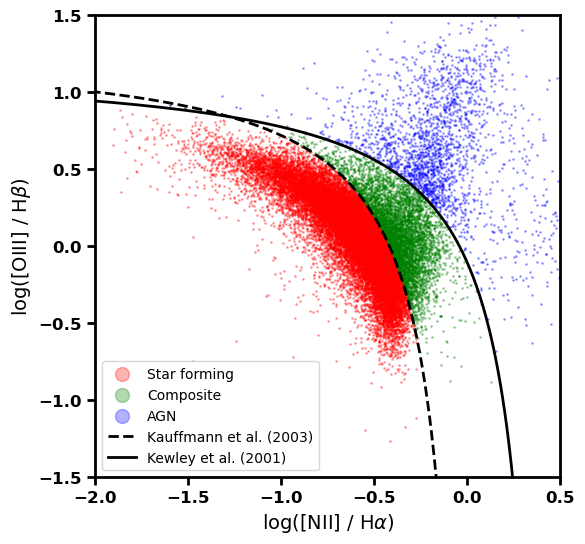

In [240]:
# Plot the BPT diagram
fig, ax = plt.subplots(figsize = (6, 6))

ax.scatter(log_NII_HA[SF], log_OIII_HB[SF], s = 1, alpha = 0.3, color = 'red', label = 'Star forming')
ax.scatter(log_NII_HA[composite], log_OIII_HB[composite], s = 1, alpha = 0.3, color = 'green', label = 'Composite')
ax.scatter(log_NII_HA[AGN], log_OIII_HB[AGN], s = 1, alpha = 0.3, color = 'blue', label = 'AGN')

# Plot the Kauffmann and Kewley lines
x_kauffmann = np.linspace(-2.5, 0.05 - 1e-3, 500)
x_kewley = np.linspace(-2.5, 0.47 - 1e-3, 500)
ax.plot(x_kauffmann, kauffmann_line(x_kauffmann), color = 'black', linestyle = '--', linewidth = 2, label = 'Kauffmann et al. (2003)')
ax.plot(x_kewley, kewley_line(x_kewley), color = 'black', linestyle = '-', linewidth = 2, label = 'Kewley et al. (2001)')

ax.set_xlim(-2.0, 0.5)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel(r'log([NII] / H$\alpha$)')
ax.set_ylabel(r'log([OIII] / H$\beta$)')
ax.legend(markerscale = 10, loc = 'lower left')

bold_ticks(ax)

plt.savefig("figs/bpt_diagram.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/bpt_diagram.png", format = "png", bbox_inches = "tight")

plt.show()

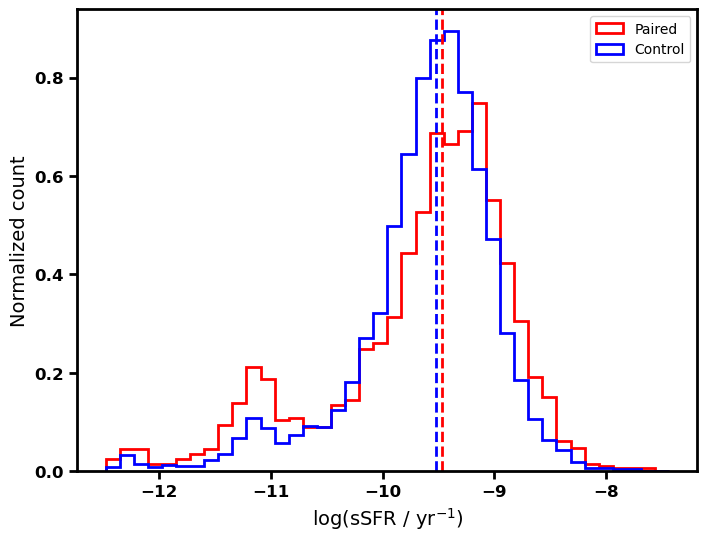

In [241]:
# Plot the log sSFR distributions of the paired and control galaxies
fig, ax = plt.subplots(figsize = (8, 6))

log_sSFR_pair = log_sSFR[p]
log_sSFR_ctrl = log_sSFR[c].ravel()

bins = np.histogram_bin_edges(np.concatenate([log_sSFR_pair, log_sSFR_ctrl]), bins = 40)
ax.hist(log_sSFR_pair, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'red', label = 'Paired')
ax.hist(log_sSFR_ctrl, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'blue', label = 'Control')

# Median of each distribution
ax.axvline(np.median(log_sSFR_pair), color = 'red', linestyle = '--', linewidth = 2)
ax.axvline(np.median(log_sSFR_ctrl), color = 'blue', linestyle = '--', linewidth = 2)

ax.set_xlabel(r'log(sSFR / yr$^{-1}$)')
ax.set_ylabel('Normalized count')
ax.legend()

bold_ticks(ax)

plt.savefig("figs/halpha_sfr_distribution.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/halpha_sfr_distribution.png", format = "png", bbox_inches = "tight")

plt.show()